# Vistas minables

En este notebook armamos las tablas que va a usar cada modelo, a partir de los archivos limpios que
guardamos en `02_limpieza_datos_ml.ipynb`.

Las dos se guardan en `data/vistas/`.

## 1. Preparación del entorno

Para correr este notebook tienen que estar los archivos de `data/clean/`
Usamos `config.py` para las rutas y la conexión a DuckDB.

In [52]:
from config import conectar, ruta_sql

con = conectar()

# Ejecuta una consulta SQL y devuelve el resultado como DataFrame.
def q(consulta):
    return con.sql(consulta).df()

## 2. Datos de partida

Creamos vistas sobre los archivos limpios y contamos cuántos usuarios distintos escuchan a cada
artista.

In [53]:
con.execute(f"CREATE OR REPLACE VIEW events_clean AS SELECT * FROM {ruta_sql('events_clean')}")
con.execute(f"CREATE OR REPLACE VIEW acoustic_clean AS SELECT * FROM {ruta_sql('acoustic_clean')}")
con.execute(f"CREATE OR REPLACE VIEW users_clean AS SELECT * FROM {ruta_sql('users_clean')}")

# Cantidad de usuarios distintos que escucharon a cada artista
con.execute("""
    CREATE OR REPLACE TEMP TABLE oyentes_artista AS
    SELECT artist_id, COUNT(DISTINCT user_id) AS oyentes
    FROM events_clean
    GROUP BY artist_id
""")

q("SELECT * FROM oyentes_artista ORDER BY oyentes DESC LIMIT 10")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,artist_id,oyentes
0,320,19886
1,1602,19140
2,46,17926
3,3,17115
4,4115,17009
5,295,16695
6,27,16338
7,185,16191
8,924,15989
9,470,15548


Antes de unir las tablas revisamos que no haya ids repetidos en usuarios ni en canciones. Si una
canción apareciera dos veces, el `JOIN` duplicaría sus escuchas.

In [54]:
q("""
    SELECT
        (SELECT COUNT(*) - COUNT(DISTINCT user_id)  FROM users_clean)    AS usuarios_repetidos,
        (SELECT COUNT(*) - COUNT(DISTINCT track_id) FROM acoustic_clean) AS canciones_repetidas
""")

,usuarios_repetidos,canciones_repetidas
0,0,0


3. Vista para clustering: vista_usuarios\

Armamos una tabla con una fila por usuario para poder agruparlos según el tipo de música que escuchan y sus hábitos de consumo. Nos quedamos con los usuarios que tienen al menos 100 escuchas con datos de audio, para que el perfil de cada uno no se base en pocas escuchas.

Características de la música que escuchan:
- Promedio de energy, valence, danceability, acousticness, instrumentalness, tempo, speechiness y loudness, para conocer qué características predominan en la música que escucha cada usuario.
- Desvío de energy y valence, para ver si escucha canciones con niveles de energía y valencia similares o variados.
Hábitos de consumo:
- Cantidad de artistas distintos que escucha.
- Proporción de escuchas que corresponden a su artista más escuchado, para ver si concentra gran parte de sus escuchas en un mismo artista.
- Popularidad media de los artistas que escucha. Medimos la popularidad según la cantidad de usuarios distintos que escucharon a cada artista y aplicamos el logaritmo para reducir las diferencias entre los artistas con muchos y pocos oyentes.
Para calcular las características musicales usamos las escuchas que tienen datos de audio, mientras que para los hábitos de consumo usamos todas las escuchas válidas.

También calculamos qué proporción de las escuchas de cada usuario tiene datos de audio, para ver con cuánta información contamos sobre la música que escucha.

Conservamos el país, la edad, el género y la cantidad total de escuchas para describir los grupos una vez realizado el clustering, pero no los incluimos en el modelo.

In [55]:
consulta_usuarios = """

-- Calculamos las características musicales de cada usuario
-- usando las escuchas de canciones con datos de audio
WITH resumen_audio AS (
    SELECT e.user_id,
           COUNT(*)                AS escuchas_con_audio,
           AVG(a.energy)           AS energy_media,
           STDDEV(a.energy)        AS energy_std,
           AVG(a.valence)          AS valence_media,
           STDDEV(a.valence)       AS valence_std,
           AVG(a.danceability)     AS dance_media,
           AVG(a.acousticness)     AS acoustic_media,
           AVG(a.instrumentalness) AS instrumental_media,
           AVG(a.tempo)            AS tempo_medio,
           AVG(a.speechiness)      AS speechiness_media,
           AVG(a.loudness)         AS loudness_media
    FROM events_clean e
    JOIN acoustic_clean a ON e.track_id = a.track_id
    GROUP BY e.user_id
    HAVING COUNT(*) >= 100
),

-- Contamos las escuchas de cada usuario por artista
por_artista AS (
    SELECT user_id, artist_id, COUNT(*) AS n
    FROM events_clean
    GROUP BY user_id, artist_id
),

-- Buscamos la cantidad de escuchas al artista más escuchado
artista_top AS (
    SELECT user_id, MAX(n) AS escuchas_top
    FROM por_artista
    GROUP BY user_id
),

-- Calculamos los hábitos de consumo usando todas las escuchas
resumen_consumo AS (
    SELECT e.user_id,
           COUNT(*)                    AS total_escuchas,
           COUNT(DISTINCT e.artist_id) AS artistas_distintos,
           AVG(LOG10(o.oyentes))       AS popularidad_media
    FROM events_clean e
    LEFT JOIN oyentes_artista o ON e.artist_id = o.artist_id
    GROUP BY e.user_id
)

-- Unimos las características musicales, los hábitos de
-- consumo y los datos demográficos de cada usuario
SELECT c.user_id,
       c.total_escuchas,
       c.artistas_distintos,
       a.escuchas_con_audio,
       a.escuchas_con_audio * 1.0 / c.total_escuchas
           AS pct_escuchas_con_audio,
       a.energy_media,
       a.energy_std,
       a.valence_media,
       a.valence_std,
       a.dance_media,
       a.acoustic_media,
       a.instrumental_media,
       a.tempo_medio,
       a.speechiness_media,
       a.loudness_media,
       c.popularidad_media,
       t.escuchas_top * 1.0 / c.total_escuchas
           AS pct_artista_top,
       u.country,
       u.age,
       u.gender
FROM resumen_audio a
JOIN resumen_consumo c ON a.user_id = c.user_id
JOIN artista_top t ON a.user_id = t.user_id
LEFT JOIN users_clean u ON a.user_id = u.user_id
"""

con.execute(f"""
    COPY ({consulta_usuarios})
    TO {ruta_sql('vista_usuarios')} (FORMAT parquet)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Revisamos cuántos usuarios quedaron, si hay nulos y cómo son las variables. `total_escuchas` cuenta solo
las escuchas de canciones que tienen datos de audio.

In [56]:
vista_usuarios = q(f"SELECT * FROM {ruta_sql('vista_usuarios')}")

print("Usuarios en la vista:", len(vista_usuarios))
print()
print(vista_usuarios.isna().sum().round)

vista_usuarios.describe().T.round(3)

Usuarios en la vista: 53289

<bound method Series.round of user_id                       0
total_escuchas                0
artistas_distintos            0
escuchas_con_audio            0
pct_escuchas_con_audio        0
energy_media                  0
energy_std                    0
valence_media                 0
valence_std                   0
dance_media                   0
acoustic_media                0
instrumental_media            0
tempo_medio                   0
speechiness_media             0
loudness_media                0
popularidad_media             0
pct_artista_top               0
country                       0
age                       11961
gender                        0
dtype: int64>


,count,mean,std,min,25%,50%,75%,max
user_id,53289.0,23144265.899623,16094451.221663,384.0,8065274.0,19857764.0,38124557.0,50900118.0
total_escuchas,53289.0,6580.227345,9081.736118,100.0,1534.0,5310.0,8865.0,345014.0
artistas_distintos,53289.0,337.370058,366.793969,1.0,113.0,229.0,434.0,13354.0
escuchas_con_audio,53289.0,6580.227345,9081.736118,100.0,1534.0,5310.0,8865.0,345014.0
pct_escuchas_con_audio,53289.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
energy_media,53289.0,0.692687,0.117028,0.102642,0.615357,0.694493,0.778673,0.964863
energy_std,53289.0,0.213505,0.039268,0.010329,0.188542,0.218539,0.241184,0.406878
valence_media,53289.0,0.424335,0.097475,0.043585,0.361969,0.429971,0.489383,0.844944
valence_std,53289.0,0.230226,0.027479,0.045913,0.215965,0.23517,0.24894,0.364258
dance_media,53289.0,0.495884,0.0791,0.103918,0.444998,0.499692,0.548037,0.861681


In [57]:
vista_usuarios.head()

,user_id,total_escuchas,artistas_distintos,escuchas_con_audio,pct_escuchas_con_audio,energy_media,energy_std,valence_media,valence_std,dance_media,acoustic_media,instrumental_media,tempo_medio,speechiness_media,loudness_media,popularidad_media,pct_artista_top,country,age,gender
0,7905607,3680,302,3680,1.0,0.821884,0.196238,0.335592,0.211909,0.414844,0.073640,0.287895,124.332703,0.088022,-6.978087,3.159925,0.065489,AR,34,m
1,39751504,2164,67,2164,1.0,0.760403,0.175593,0.485629,0.216392,0.592255,0.126748,0.048231,121.426308,0.067360,-5.156538,3.158591,0.530499,RU,16,f
2,17704917,3847,469,3847,1.0,0.586941,0.272040,0.381531,0.266452,0.490801,0.325997,0.249447,118.697209,0.077072,-9.907148,3.596460,0.060567,GB,20,f
3,42542639,3339,1059,3339,1.0,0.794707,0.228485,0.365680,0.230622,0.461375,0.117022,0.225909,129.592754,0.088108,-6.689279,2.835937,0.032345,RU,21,m
4,48042809,927,119,927,1.0,0.740683,0.214290,0.349777,0.205439,0.412210,0.112275,0.304441,125.464551,0.065271,-7.596577,3.551131,0.073355,BE,30,m


### 3.1. Correlación entre variables

Antes de aplicar el clustering, analizamos la correlación entre las variables para ver si hay algunas que aportan información similar. Si dos variables están muy relacionadas, usar ambas podría darle más peso a una misma característica al momento de formar los grupos.

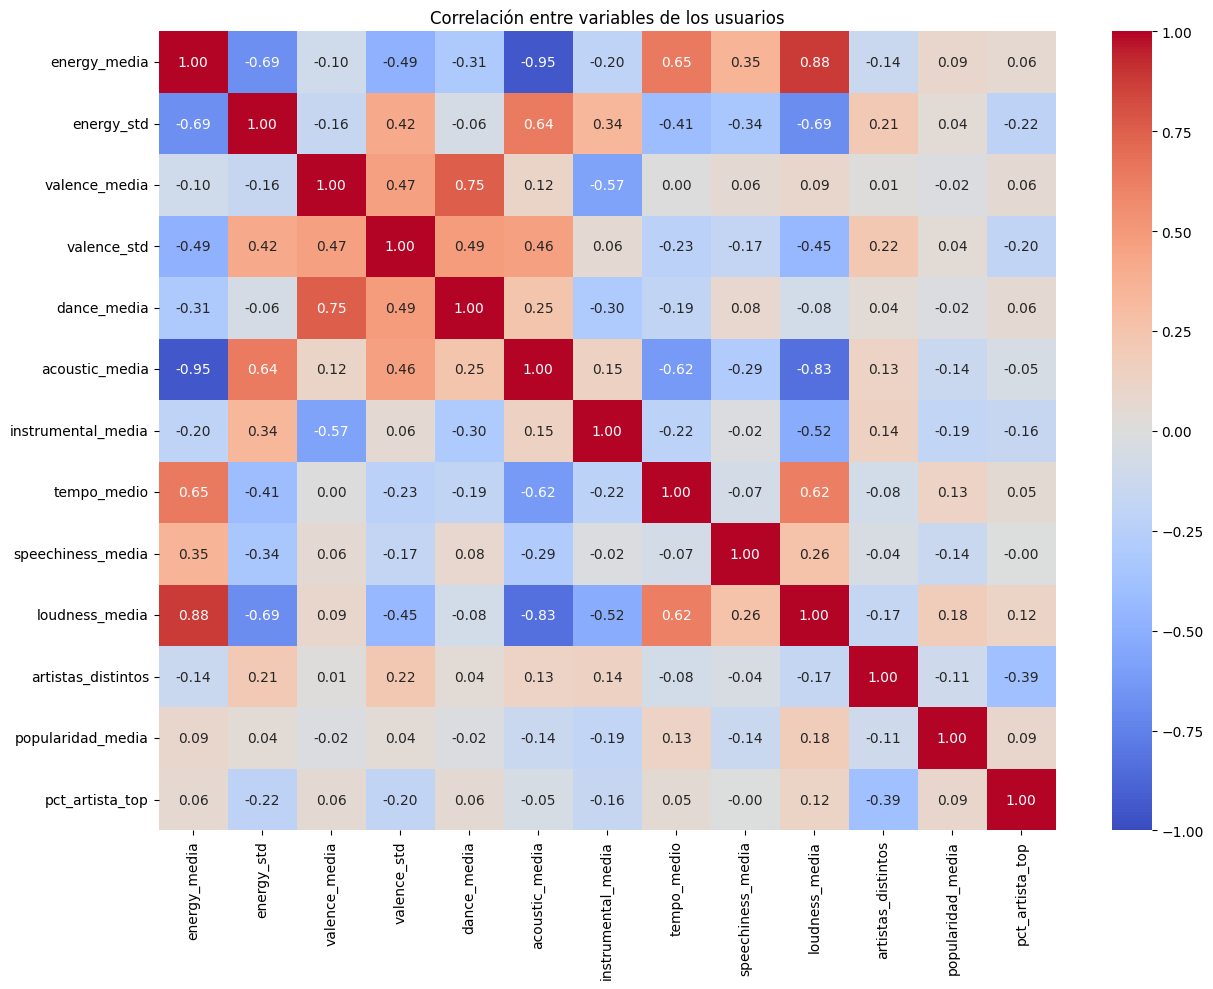

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cargamos la tabla de usuarios
vista_usuarios = q(f"""
    SELECT *
    FROM {ruta_sql('vista_usuarios')}
""")

# Seleccionamos las posibles variables para el clustering
variables_clustering = [
    "energy_media",
    "energy_std",
    "valence_media",
    "valence_std",
    "dance_media",
    "acoustic_media",
    "instrumental_media",
    "tempo_medio",
    "speechiness_media",
    "loudness_media",
    "artistas_distintos",
    "popularidad_media",
    "pct_artista_top"
]

# Calculamos la matriz de correlación de Pearson
corr = vista_usuarios[variables_clustering].corr()

# Graficamos la matriz de correlación
plt.figure(figsize=(13, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlación entre variables de los usuarios")
plt.tight_layout()
plt.show()

### 3.2. Variables con mayor correlación
Además del gráfico, podemos mostrar directamente los pares de variables que tienen una correlación alta, tanto positiva como negativa.

In [59]:
# Mostramos los pares de variables con una correlación
# mayor o igual a 0.7 en valor absoluto

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        valor = corr.iloc[i, j]

        if abs(valor) >= 0.7:
            print(f"{corr.columns[i]} - {corr.columns[j]}: {valor:.3f}")

energy_media - acoustic_media: -0.951
energy_media - loudness_media: 0.879
valence_media - dance_media: 0.750
acoustic_media - loudness_media: -0.834


### 3.3. Relación entre cantidad de escuchas y artistas distintos
Queremos saber si la cantidad de artistas distintos está muy condicionada por el nivel de actividad del usuario.
Analizamos la relación entre la cantidad total de escuchas y la cantidad de artistas distintos, ya que los usuarios con más escuchas tienen más oportunidades de escuchar diferentes artistas.

In [60]:
vista_usuarios[["total_escuchas", "artistas_distintos"]].corr()

,total_escuchas,artistas_distintos
total_escuchas,1.000000,0.465953
artistas_distintos,0.465953,1.000000


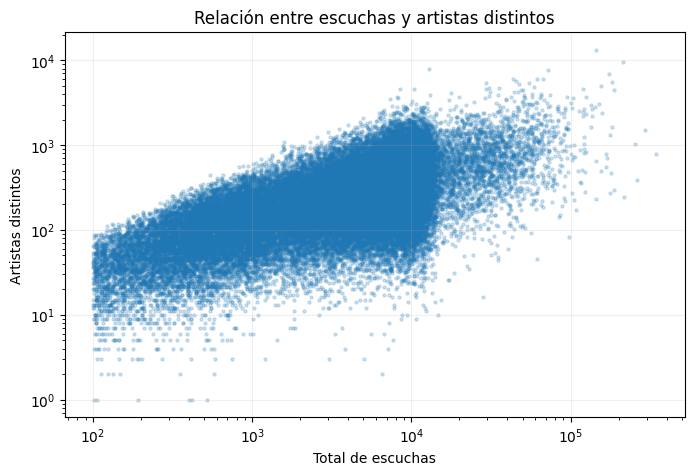

In [61]:
plt.figure(figsize=(8, 5))

plt.scatter(
    vista_usuarios["total_escuchas"],
    vista_usuarios["artistas_distintos"],
    alpha=0.2,
    s=5
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Total de escuchas")
plt.ylabel("Artistas distintos")
plt.title("Relación entre escuchas y artistas distintos")
plt.grid(alpha=0.2)
plt.show()

In [62]:
vista_usuarios[["total_escuchas", "artistas_distintos"]].corr(
    method="spearman"
)

,total_escuchas,artistas_distintos
total_escuchas,1.000000,0.609677
artistas_distintos,0.609677,1.000000


### 4. Vista para recomendación: vista_usuario_artista

Armamos una tabla con una fila por cada combinación de usuario y artista, donde contamos cuántas veces el usuario escuchó a ese artista.

Como no tenemos puntuaciones, usamos la cantidad de escuchas como una señal del interés del usuario por cada artista.

Nos quedamos con los 10.000 artistas con más oyentes para reducir el tamaño de la matriz y evitar trabajar con artistas de los que tenemos muy poca información.

Esta tabla resume todo el historial de escuchas sin guardar las fechas. Para entrenar y evaluar el recomendador vamos a separar los datos por fecha antes de agruparlos, para no utilizar información del período de prueba durante el entrenamiento.

In [63]:
consulta_ua = """

-- Seleccionamos los artistas con más oyentes
WITH top_artistas AS (
    SELECT artist_id
    FROM oyentes_artista
    ORDER BY oyentes DESC, artist_id
    LIMIT 5000
),

-- Contamos las escuchas de cada usuario por artista
usuario_artista AS (
    SELECT e.user_id,
           e.artist_id,
           COUNT(*) AS escuchas
    FROM events_clean e
    JOIN top_artistas t ON e.artist_id = t.artist_id
    GROUP BY e.user_id, e.artist_id
)

SELECT *
FROM usuario_artista
"""

con.execute(f"""
    COPY ({consulta_ua})
    TO {ruta_sql('vista_usuario_artista')} (FORMAT parquet)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [64]:
# Revisamos cuántos usuarios, artistas y escuchas quedaron
q(f"""
    SELECT COUNT(*) AS filas,
           COUNT(DISTINCT user_id) AS usuarios,
           COUNT(DISTINCT artist_id) AS artistas,
           SUM(escuchas) AS total_escuchas
    FROM {ruta_sql('vista_usuario_artista')}
""")

,filas,usuarios,artistas,total_escuchas
0,10370590,55001,5000,256459288.0


In [65]:
# Calculamos el porcentaje de escuchas que conservamos
q(f"""
    SELECT
        (SELECT SUM(escuchas)
         FROM {ruta_sql('vista_usuario_artista')}) AS escuchas_conservadas,
        COUNT(*) AS escuchas_totales,
        ROUND(
            100.0 * (SELECT SUM(escuchas)
                     FROM {ruta_sql('vista_usuario_artista')})
            / COUNT(*), 2
        ) AS pct_conservado
    FROM events_clean
""")

,escuchas_conservadas,escuchas_totales,pct_conservado
0,256459288.0,350741953,73.12


In [66]:
# Calculamos qué porcentaje de usuarios conservamos
q(f"""
    SELECT
        COUNT(DISTINCT user_id) AS usuarios_conservados,
        (SELECT COUNT(DISTINCT user_id)
         FROM events_clean) AS usuarios_totales,
        ROUND(
            100.0 * COUNT(DISTINCT user_id) /
            (SELECT COUNT(DISTINCT user_id) FROM events_clean),
            2
        ) AS pct_usuarios
    FROM {ruta_sql('vista_usuario_artista')}
""")

,usuarios_conservados,usuarios_totales,pct_usuarios
0,55001,55143,99.74


Calculamos la densidad: qué porcentaje de todas las combinaciones usuario-artista posibles tiene
alguna escucha. Si es baja, en el recomendador conviene usar una matriz dispersa (que guarda solo los
valores distintos de cero).

In [67]:
resumen_ua = q(f"""
    SELECT COUNT(*)                  AS pares,
           COUNT(DISTINCT user_id)   AS usuarios,
           COUNT(DISTINCT artist_id) AS artistas,
           MEDIAN(escuchas)          AS mediana_escuchas,
           MAX(escuchas)             AS max_escuchas
    FROM {ruta_sql('vista_usuario_artista')}
""")

resumen_ua["densidad_%"] = resumen_ua["pares"] / (resumen_ua["usuarios"] * resumen_ua["artistas"]) * 100
resumen_ua

,pares,usuarios,artistas,mediana_escuchas,max_escuchas,densidad_%
0,10370590,55001,5000,4.0,181440,3.771055


nos quedaron 12.717.100 pares usuario-artista, correspondientes a 55.077 usuarios y 10.000 artistas. La densidad de la matriz es del 2,31%, ya que cada usuario escucha solo una pequeña parte de los artistas disponibles. Por este motivo vamos a trabajar con una matriz dispersa.

También se observa una gran diferencia entre la mediana de escuchas por par (4) y el máximo (181.440), por lo que vamos a revisar la distribución de las escuchas antes de decidir cómo utilizar esta variable en el modelo.

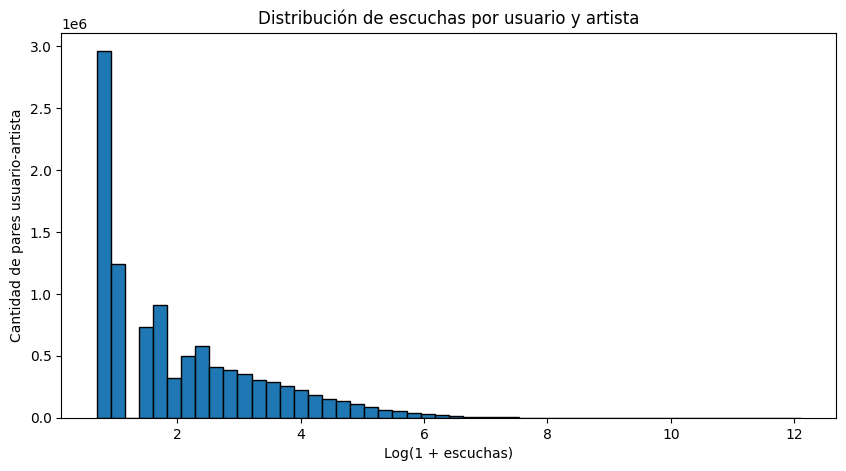

In [68]:
import numpy as np
# Analizamos la distribución de las escuchas por usuario y artista
distribucion_ua = q(f"""
    SELECT escuchas
    FROM {ruta_sql('vista_usuario_artista')}
""")

plt.figure(figsize=(10, 5))
plt.hist(
    np.log1p(distribucion_ua["escuchas"]),
    bins=50,
    edgecolor="black"
)

plt.xlabel("Log(1 + escuchas)")
plt.ylabel("Cantidad de pares usuario-artista")
plt.title("Distribución de escuchas por usuario y artista")
plt.show()

la mayoría de los pares usuario-artista tiene pocas escuchas, aunque hay casos en los que un usuario escucha muchas veces a un mismo artista. Se observa una cola larga hacia la derecha incluso después de aplicar el logaritmo.

In [69]:
# Primeras filas, ordenadas para ver juntos los artistas de cada usuario.
# No la cargamos entera porque tiene más de 12 millones de filas.
q(f"""
    SELECT *
    FROM {ruta_sql('vista_usuario_artista')}
    ORDER BY user_id, escuchas DESC
    LIMIT 10
""")

,user_id,artist_id,escuchas
0,384,67,651
1,384,17352,458
2,384,2583,384
3,384,15202,362
4,384,9037,348
5,384,7993,320
6,384,1996,299
7,384,47,294
8,384,362,241
9,384,8450,219


**Observaciones:**

Quedaron 12.691.416 pares de 53.271 usuarios y 10.000 artistas. Hay 18 usuarios del clustering que no
aparecen porque no escuchan a ninguno de esos artistas.

La densidad es de 2,38%: de cada 100 combinaciones, solo 2 o 3 tienen escuchas. La mediana es 4
escuchas por par y el máximo 181.440, así que en el recomendador vamos a probar con `log1p(escuchas)`
(el logaritmo de 1 + escuchas) para que los valores altos no tapen al resto.

Las dos quedan en `data/vistas/` y son las que usamos en los notebooks de cada modelo.